# LSTMs for Text Classification

**Dataset:** AG_NEWS (News topic classification: World, Sports, Business, Sci/Tech)

**Instructions:** Complete the simple `# TODO` sections marked with `None`. Run all cells top-to-bottom to train and evaluate your model.

In [1]:
# Run this cell to install dependencies and load the dataset
!pip install -q datasets

In [2]:
import re
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from datasets import load_dataset

# GPU available bhaye CUDA use gareko, natra CPU use gareko
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Current device print gareko
print(f"Using device: {device}")

Using device: cuda


### Step 1: Vocabulary & Preprocessing
Neural networks need numbers, not raw text. We will build a vocabulary to map words to integers.

In [3]:
def tokenizer(text):
    return re.findall(r"[a-z0-9]+", text.lower())

# AG_NEWS dataset load gareko
ag_news = load_dataset('fancyzhx/ag_news')
train_data = ag_news['train']
test_data = ag_news['test']

# Dataset bata token haru extract gareko
def yield_tokens(data_iter):
    for example in data_iter:
        yield tokenizer(example['text'])

from collections import Counter

# Sabai training words count gareko
counter = Counter()
for tokens in yield_tokens(train_data):
    counter.update(tokens)

# Vocabulary create gareko
itos = ['<unk>', '<pad>'] + list(counter.keys())
stoi = {word: idx for idx, word in enumerate(itos)}

# Unknown ra Padding token ko index store gareko
UNK_IDX = stoi['<unk>']
PAD_IDX = stoi['<pad>']

# Text lai numerical indices ma convert gareko
def numericalize(text):
    return [stoi.get(tok, UNK_IDX) for tok in tokenizer(text)]

print(f"Vocabulary size: {len(itos):,}")

# Batch prepare gareko
def collate_batch(batch):
    label_list, text_list = [], []

    for example in batch:
        # Label collect gareko
        label_list.append(example['label'])

        # Text lai tensor ma convert gareko
        processed_text = torch.tensor(
            numericalize(example['text']),
            dtype=torch.int64
        )
        text_list.append(processed_text)

    # Sabai sentence same length banauna padding gareko
    padded_texts = nn.utils.rnn.pad_sequence(
        text_list,
        batch_first=True,
        padding_value=PAD_IDX
    )

    # Labels tensor ma convert gareko
    labels = torch.tensor(label_list, dtype=torch.int64)

    return padded_texts, labels

# Fast training ko lagi sano subset use gareko
train_list = list(train_data)[:5000]
test_list = list(test_data)[:1000]

# DataLoader create gareko
tr_ld = DataLoader(
    train_list,
    batch_size=32,
    shuffle=True,
    collate_fn=collate_batch
)

te_ld = DataLoader(
    test_list,
    batch_size=32,
    shuffle=False,
    collate_fn=collate_batch
)

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

Vocabulary size: 65,017


### Step 2: Build the LSTM Model
Construct a simple LSTM text classifier.

In [4]:
class SimpleLSTM(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes):
        super().__init__()

        # Word embedding layer initialize gareko
        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=PAD_IDX
        )

        # LSTM layer initialize gareko
        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        # Final classification layer initialize gareko
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, text):
        # Input tokens lai embedding vectors ma convert gareko
        embedded = self.embedding(text)

        # Embedded text LSTM bata pass gareko
        output, (hidden, cell) = self.lstm(embedded)

        # Last LSTM layer ko final hidden state use gareko
        final_hidden = hidden[-1]

        # Final prediction ko lagi fully connected layer use gareko
        logits = self.fc(final_hidden)

        return logits


model = SimpleLSTM(
    vocab_size=len(itos),
    embed_dim=64,
    hidden_dim=128,
    num_classes=4
).to(device)

print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")

Model parameters: 4,260,932


### Step 3: Train and Evaluate
Write the core steps of the PyTorch training loop.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.005)
criterion = nn.CrossEntropyLoss()

for epoch in range(3):
    model.train()

    total_loss, correct, total = 0, 0, 0

    for texts, labels in tr_ld:
        # Data lai selected device ma move gareko
        texts, labels = texts.to(device), labels.to(device)

        # Previous gradients clear gareko
        optimizer.zero_grad()

        # Forward pass gareko
        predictions = model(texts)

        # Prediction ra actual labels bich loss calculate gareko
        loss = criterion(predictions, labels)

        # Backpropagation gareko
        loss.backward()

        # Model weights update gareko
        optimizer.step()

        total_loss += loss.item()

        # Correct prediction count gareko
        correct += (predictions.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_acc = correct / total

    # Evaluation Phase
    model.eval()

    val_correct, val_total = 0, 0

    with torch.no_grad():
        for texts, labels in te_ld:
            texts, labels = texts.to(device), labels.to(device)

            # Validation prediction gareko
            preds = model(texts)

            # Validation accuracy calculate gareko
            val_correct += (preds.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_acc = val_correct / val_total

    print(
        f"Epoch {epoch+1}/3 | Train Acc: {train_acc:.1%} | Val Acc: {val_acc:.1%}"
    )

Epoch 1/3 | Train Acc: 28.9% | Val Acc: 25.2%
Epoch 2/3 | Train Acc: 30.1% | Val Acc: 25.3%
Epoch 3/3 | Train Acc: 32.9% | Val Acc: 40.5%


## Step 4: Reflection

### 1. What does the `padding_idx` argument do in the `nn.Embedding` layer?

The `padding_idx` argument tells the Embedding layer which index represents the padding token.

In text classification, every sentence can have a different length. To process multiple sentences in the same batch, shorter sentences are filled with a special token called `<pad>`.

**Example:**

**Before padding:**

```text
Sentence 1: [hello, world]
Sentence 2: [hello]
```

**After padding:**

```text
Sentence 1: [hello, world]
Sentence 2: [hello, <pad>]
```

The `padding_idx` prevents the embedding value of the `<pad>` token from being updated during training because padding does not contain any meaningful information.

This helps the model focus only on real words and prevents padding values from affecting the learning process.

---

### 2. Why do we extract `hidden[-1]` instead of using the raw `output` from the LSTM for classification?

The LSTM returns two main outputs:

- **`output`**: Contains hidden states for every word position in the sequence.
- **`hidden`**: Contains the final hidden state after processing the complete sentence.

For classification, we need one fixed representation of the whole text instead of hidden states for every individual word.

`hidden[-1]` represents the final hidden state of the last LSTM layer, which contains the information learned from the complete sequence.

**Example:**

```text
Input Text
    ↓
Embedding Layer
    ↓
LSTM processes all words
    ↓
Final Hidden State (hidden[-1])
    ↓
Fully Connected Layer
    ↓
Class Prediction
```

Therefore, we use `hidden[-1]` because it provides a compact summary of the entire text, which is suitable for classification and prediction tasks.

### Step 5: Inference
Now that the model is trained, let's use it to classify a brand new headline that it has never seen before.

In [6]:
class_names = ['World', 'Sports', 'Business', 'Sci/Tech']

def predict(text, model):
    model.eval()

    # Raw text lai token ids ma convert gareko
    text_tensor = torch.tensor(
        numericalize(text),
        dtype=torch.int64
    ).to(device)

    # Batch dimension add gareko
    text_tensor = text_tensor.unsqueeze(0)

    with torch.no_grad():
        # Model bata prediction logits calculate gareko
        logits = model(text_tensor)

        # Highest score bhayeko class index find gareko
        predicted_idx = logits.argmax(1).item()

    return class_names[predicted_idx]


sample_headlines = [
    "Manchester United wins dramatic final in extra time",
    "Central bank raises interest rates to combat inflation",
    "NASA's new telescope captures images of distant galaxy",
    "Peace talks resume between the two neighboring countries"
]

for headline in sample_headlines:
    prediction = predict(headline, model)
    print(f"'{headline}' -> {prediction}")

'Manchester United wins dramatic final in extra time' -> Business
'Central bank raises interest rates to combat inflation' -> Sci/Tech
'NASA's new telescope captures images of distant galaxy' -> Sci/Tech
'Peace talks resume between the two neighboring countries' -> World


## Output Summary

The AG_NEWS dataset was loaded successfully from Hugging Face. The dataset contains:

- **Training samples:** 120,000
- **Testing samples:** 7,600

The vocabulary was created successfully with:

```text
Vocabulary size: 65,017
```

This means the model learned around **65 thousand unique words** from the training dataset.

The LSTM model was created successfully with:

```text
Model parameters: 4,260,932
```

This means the model has around **4.2 million trainable parameters** that are updated during training.

---

## Training Performance

The model was trained for **3 epochs**.

**Results:**

```text
Epoch 1/3 | Train Acc: 28.9% | Val Acc: 25.2%
Epoch 2/3 | Train Acc: 30.1% | Val Acc: 25.3%
Epoch 3/3 | Train Acc: 32.9% | Val Acc: 40.5%
```

During training, the accuracy increased gradually. The validation accuracy improved significantly in the third epoch, which shows that the model started learning useful patterns from the news text.

However, the accuracy is still relatively low because:

- The model was trained only on **5,000 training samples** instead of the full dataset.
- The training was done for only **3 epochs**.
- This is a simple LSTM model without advanced techniques such as **dropout**, **bidirectional LSTM**, or **pretrained embeddings**.

---

## Inference Result Summary

The trained model was tested on new headlines:

```text
Manchester United wins dramatic final in extra time -> Business
Central bank raises interest rates to combat inflation -> Sci/Tech
NASA's new telescope captures images of distant galaxy -> Sci/Tech
Peace talks resume between the two neighboring countries -> World
```

The model correctly predicted:

- NASA headline → **Sci/Tech**
- Peace talks headline → **World**

The Sports and Business related headlines were classified incorrectly. This indicates that the model learned some general language patterns but still struggles with specific topic recognition.

---

## Overall Conclusion

The LSTM text classification pipeline worked successfully.

The complete process was completed:

```text
Text Data
    ↓
Tokenization
    ↓
Vocabulary Creation
    ↓
Numericalization
    ↓
Embedding Layer
    ↓
LSTM Model Training
    ↓
Classification
    ↓
New Text Prediction
```

The model is able to classify unseen headlines, but its performance can be improved by:

- Training on the full dataset instead of a small subset.
- Increasing the number of training epochs.
- Using larger embedding dimensions and hidden sizes.
- Adding **dropout** to reduce overfitting.
- Using a **bidirectional LSTM** to capture context from both directions.
- Initializing the embedding layer with **pretrained word embeddings** such as GloVe or FastText.
- Performing hyperparameter tuning for better optimization and generalization.

# Full Dataset

# Step 1: Install Required Libraries

In this step, we install the libraries needed for this project.

- `datasets` is used to download and load the AG News dataset from Hugging Face.
- The other required libraries, such as PyTorch, are already available in Google Colab.

This step only needs to be run once.

# Step 2: Import Required Libraries

In this step, we import all the libraries required for the project.

These libraries help us with:
- Loading the dataset
- Processing text
- Building the vocabulary
- Creating DataLoaders
- Building and training the LSTM model
- Evaluating the model
- Plotting training results
- Saving and loading the trained model

Importing everything at the beginning keeps the notebook organized and avoids importing the same library multiple times.

In [14]:
# Regular expression library for text cleaning and tokenization
import re

# Random seed for reproducibility
import random

# Counter is used to count word frequencies
from collections import Counter

# PyTorch libraries
import torch
import torch.nn as nn

# Dataset and DataLoader utilities
from torch.utils.data import DataLoader

# Pad variable-length sequences
from torch.nn.utils.rnn import pad_sequence

# Load AG News dataset
from datasets import load_dataset

# Plot training and validation curves
import matplotlib.pyplot as plt

# Step 3: Set Random Seed and Select Device

To make our results more consistent, we first set a random seed. This helps reduce variations between different runs of the notebook.

Next, we check whether a GPU is available. If a GPU is available, the model will use it for faster training. Otherwise, the model will run on the CPU.

Using a GPU can significantly reduce the training time, especially when working with the full AG News dataset.

In [15]:
# Set a random seed for reproducibility
SEED = 42

random.seed(SEED)
torch.manual_seed(SEED)

# If a GPU is available, also set its seed
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# Select the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Using device: {device}")

# Print GPU name if available
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Using device: cuda
GPU: Tesla T4


# Step 4: Load the Full AG News Dataset

In this step, we download the complete AG News dataset using the Hugging Face `datasets` library.

The dataset is already divided into:
- Training set
- Test set

Each news article contains:
- `text`: the news headline and description
- `label`: the category of the news

The four categories are:
- World
- Sports
- Business
- Sci/Tech

After loading the dataset, we will check:
- The number of training and test samples
- The available features
- A sample news article

In [18]:
# Load the complete AG News dataset
ag_news = load_dataset("fancyzhx/ag_news")

# Separate training and test datasets
train_data = ag_news["train"]
test_data = ag_news["test"]

print("Dataset loaded successfully!\n")

print(f"Training samples : {len(train_data):,}")
print(f"Testing samples  : {len(test_data):,}")

print("\nFeatures:")
print(train_data.features)

print("\nFirst Training Sample:")
print(train_data[0])

Dataset loaded successfully!

Training samples : 120,000
Testing samples  : 7,600

Features:
{'text': Value('string'), 'label': ClassLabel(names=['World', 'Sports', 'Business', 'Sci/Tech'])}

First Training Sample:
{'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}


# Step 5: Create the Tokenizer

Machine learning models cannot understand raw text directly. Before we can build our vocabulary, we first need to split each news article into individual words. This process is called **tokenization**.

In this project, we use a simple regular expression tokenizer that:

- Converts all text to lowercase
- Removes punctuation and special characters
- Keeps only letters and numbers

The output of the tokenizer is a list of words (tokens), which will later be used to build the vocabulary.

In [19]:
# Function to tokenize text
def tokenizer(text):
    """
    Convert text to lowercase and split it into words.
    Only letters and numbers are kept.
    """
    return re.findall(r"[a-z0-9]+", text.lower())

In [20]:
# Example sentence
sample_text = "NASA's new telescope captures amazing images of distant galaxies!"

# Tokenize the sentence
tokens = tokenizer(sample_text)

print("Original Text:")
print(sample_text)

print("\nTokens:")
print(tokens)

Original Text:
NASA's new telescope captures amazing images of distant galaxies!

Tokens:
['nasa', 's', 'new', 'telescope', 'captures', 'amazing', 'images', 'of', 'distant', 'galaxies']


# Step 6: Build the Vocabulary

After tokenizing the text, we build a vocabulary from the training dataset.

A vocabulary is a collection of unique words that the model is allowed to learn.

To make training more efficient, we keep only the 30,000 most frequent words. Any word that is not in the vocabulary will be treated as an unknown word (`<unk>`).

We also create two mappings:

- `stoi` (String to Index): Converts a word into a numerical ID.
- `itos` (Index to String): Converts a numerical ID back into a word.

Special tokens:
- `<unk>`: Used for unknown words.
- `<pad>`: Used to pad shorter sentences within a batch.

In [21]:
# Function to yield tokens from the training dataset
def yield_tokens(data_iter):
    for example in data_iter:
        yield tokenizer(example["text"])


# Count the frequency of every word
counter = Counter()

for tokens in yield_tokens(train_data):
    counter.update(tokens)

print(f"Total unique words found: {len(counter):,}")

Total unique words found: 65,015


In [22]:
# Maximum vocabulary size
MAX_VOCAB_SIZE = 30000

# Keep only the most frequent words
most_common_words = counter.most_common(MAX_VOCAB_SIZE)

# Create index-to-string mapping
itos = ["<unk>", "<pad>"] + [
    word for word, _ in most_common_words
]

# Create string-to-index mapping
stoi = {
    word: idx
    for idx, word in enumerate(itos)
}

# Special token indices
UNK_IDX = stoi["<unk>"]
PAD_IDX = stoi["<pad>"]

print(f"Vocabulary size: {len(itos):,}")
print(f"Unknown token index : {UNK_IDX}")
print(f"Padding token index : {PAD_IDX}")

Vocabulary size: 30,002
Unknown token index : 0
Padding token index : 1


In [23]:
print("First 20 vocabulary words:\n")

for i, word in enumerate(itos[:20]):
    print(f"{i:2d} -> {word}")

First 20 vocabulary words:

 0 -> <unk>
 1 -> <pad>
 2 -> the
 3 -> to
 4 -> a
 5 -> of
 6 -> in
 7 -> and
 8 -> s
 9 -> on
10 -> for
11 -> 39
12 -> that
13 -> with
14 -> as
15 -> at
16 -> its
17 -> is
18 -> new
19 -> by


# Step 7: Convert Text into Numerical IDs

Deep learning models cannot process text directly. Instead, every word must be converted into a numerical ID using the vocabulary created in the previous step.

In this step, we will:

- Convert each word into its corresponding index.
- Replace unknown words with the `<unk>` token.
- Limit each sentence to a maximum length of 100 words.

Limiting the sequence length helps reduce memory usage and speeds up training while still preserving most of the important information in each news article.

In [24]:
# Maximum number of words to keep in each news article
MAX_SEQ_LENGTH = 100


def numericalize(text):
    """
    Convert text into a list of word indices.
    Unknown words are replaced with UNK_IDX.
    Sentences longer than MAX_SEQ_LENGTH are truncated.
    """

    # Tokenize the text
    tokens = tokenizer(text)

    # Limit sentence length
    tokens = tokens[:MAX_SEQ_LENGTH]

    # Convert words to indices
    indices = [
        stoi.get(token, UNK_IDX)
        for token in tokens
    ]

    return indices

In [25]:
sample_text = "Apple launches a new AI model for smartphones."

print("Original Text:")
print(sample_text)

print("\nToken IDs:")
print(numericalize(sample_text))

Original Text:
Apple launches a new AI model for smartphones.

Token IDs:
[307, 1029, 4, 18, 12484, 2047, 10, 8014]


# Step 8: Create the DataLoader

Deep learning models are trained using mini-batches instead of processing one sample at a time.

However, news articles have different lengths. Some articles may contain 20 words, while others may contain 80 or more.

To create batches, every sentence in the batch must have the same length.

In this step, we will:

- Convert each news article into numerical IDs.
- Pad shorter sentences using the `<pad>` token.
- Create DataLoaders for the training and testing datasets.

The DataLoader automatically creates mini-batches, shuffles the training data, and prepares the data for efficient training.

In [26]:
def collate_batch(batch):
    """
    Prepare one mini-batch for training.
    """

    text_list = []
    label_list = []

    for sample in batch:

        # Convert text into numerical IDs
        text = torch.tensor(
            numericalize(sample["text"]),
            dtype=torch.long
        )

        text_list.append(text)

        label_list.append(sample["label"])

    # Pad all sentences in the batch
    padded_text = pad_sequence(
        text_list,
        batch_first=True,
        padding_value=PAD_IDX
    )

    labels = torch.tensor(
        label_list,
        dtype=torch.long
    )

    return padded_text, labels

In [27]:
# Batch size
BATCH_SIZE = 64

# Training DataLoader
train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch
)

# Testing DataLoader
test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


In [28]:
# Get one mini-batch
texts, labels = next(iter(train_loader))

print("Text batch shape :", texts.shape)
print("Label batch shape:", labels.shape)

print("\nFirst five labels:")
print(labels[:5])

Text batch shape : torch.Size([64, 70])
Label batch shape: torch.Size([64])

First five labels:
tensor([1, 3, 3, 3, 1])


# Step 9: Build the Bidirectional LSTM Model

In this step, we build the neural network that will classify news articles into one of the four categories.

The model consists of the following layers:

1. **Embedding Layer**
   - Converts each word index into a dense vector representation.

2. **Bidirectional LSTM**
   - Reads the sentence from both left-to-right and right-to-left.
   - This helps the model understand context from both directions.

3. **Dropout Layer**
   - Randomly drops some neurons during training.
   - This helps reduce overfitting and improves generalization.

4. **Fully Connected Layer**
   - Produces the final prediction for one of the four news categories.

In [29]:
class BiLSTMClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        output_dim,
        padding_idx,
        dropout=0.5
    ):
        super().__init__()

        # Word Embedding Layer
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=padding_idx
        )

        # Bidirectional LSTM
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        # Dropout Layer
        self.dropout = nn.Dropout(dropout)

        # Fully Connected Layer
        self.fc = nn.Linear(
            hidden_dim * 2,
            output_dim
        )

    def forward(self, text):

        # Convert word IDs into embedding vectors
        embedded = self.embedding(text)

        # Pass embeddings through the BiLSTM
        output, (hidden, cell) = self.lstm(embedded)

        # Concatenate the final forward and backward hidden states
        hidden = torch.cat(
            (hidden[-2], hidden[-1]),
            dim=1
        )

        # Apply dropout
        hidden = self.dropout(hidden)

        # Final prediction
        logits = self.fc(hidden)

        return logits

In [30]:
# Model hyperparameters
EMBEDDING_DIM = 128
HIDDEN_DIM = 128
OUTPUT_DIM = 4
DROPOUT = 0.5

# Create the model
model = BiLSTMClassifier(
    vocab_size=len(itos),
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    output_dim=OUTPUT_DIM,
    padding_idx=PAD_IDX,
    dropout=DROPOUT
)

# Move the model to GPU or CPU
model = model.to(device)

print(model)

# Count trainable parameters
num_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"\nTrainable Parameters: {num_params:,}")

BiLSTMClassifier(
  (embedding): Embedding(30002, 128, padding_idx=1)
  (lstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=256, out_features=4, bias=True)
)

Trainable Parameters: 4,105,476


# Step 10: Configure the Training Process

Before training the model, we need to define how it will learn from the data.

In this step, we configure:

- **Loss Function:** Measures how different the model's predictions are from the true labels.
- **Optimizer:** Updates the model's parameters to reduce the loss.
- **Learning Rate:** Controls how large each update step is during training.
- **Number of Epochs:** Specifies how many times the model will go through the entire training dataset.

We also create lists to store the training history so that we can visualize the model's performance after training.

In [31]:
# Loss Function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Training Configuration
NUM_EPOCHS = 10

# Lists to store training history
train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

print("Training configuration completed successfully!\n")

print(f"Loss Function : {criterion}")
print(f"Optimizer     : Adam")
print(f"Learning Rate : {optimizer.param_groups[0]['lr']}")
print(f"Epochs        : {NUM_EPOCHS}")

Training configuration completed successfully!

Loss Function : CrossEntropyLoss()
Optimizer     : Adam
Learning Rate : 0.001
Epochs        : 10


# Step 11: Train and Evaluate the Model

In this step, we train the Bidirectional LSTM model using the training dataset and evaluate its performance on the test dataset after each epoch.

The training process follows these steps:

1. Load one mini-batch of training data.
2. Move the data to the selected device (GPU or CPU).
3. Perform a forward pass through the model.
4. Calculate the loss.
5. Compute gradients using backpropagation.
6. Update the model parameters using the optimizer.

After each training epoch, we evaluate the model on the test dataset and calculate:

- Training Loss
- Training Accuracy
- Validation Loss
- Validation Accuracy

The model with the highest validation accuracy is automatically saved for later use.

In [32]:
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    """
    Train the model for one epoch.
    """

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for texts, labels in dataloader:

        # Move data to device
        texts = texts.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(texts)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Statistics
        total_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()

        total += labels.size(0)

    avg_loss = total_loss / len(dataloader)
    accuracy = correct / total

    return avg_loss, accuracy

In [33]:
def evaluate(model, dataloader, criterion, device):
    """
    Evaluate the model.
    """

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for texts, labels in dataloader:

            texts = texts.to(device)
            labels = labels.to(device)

            outputs = model(texts)

            loss = criterion(outputs, labels)

            total_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()

            total += labels.size(0)

    avg_loss = total_loss / len(dataloader)
    accuracy = correct / total

    return avg_loss, accuracy

In [34]:
best_val_accuracy = 0.0

for epoch in range(NUM_EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_accuracy = evaluate(
        model,
        test_loader,
        criterion,
        device
    )

    # Store history
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    # Save the best model
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            "best_bilstm_ag_news.pth"
        )

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2%}"
    )

print("\nTraining completed successfully!")
print(f"Best Validation Accuracy: {best_val_accuracy:.2%}")

Epoch [1/10] | Train Loss: 0.5115 | Train Acc: 81.50% | Val Loss: 0.3254 | Val Acc: 89.14%
Epoch [2/10] | Train Loss: 0.2702 | Train Acc: 91.09% | Val Loss: 0.2888 | Val Acc: 90.30%
Epoch [3/10] | Train Loss: 0.2102 | Train Acc: 93.11% | Val Loss: 0.2721 | Val Acc: 91.17%
Epoch [4/10] | Train Loss: 0.1686 | Train Acc: 94.51% | Val Loss: 0.2671 | Val Acc: 91.45%
Epoch [5/10] | Train Loss: 0.1345 | Train Acc: 95.55% | Val Loss: 0.2734 | Val Acc: 91.49%
Epoch [6/10] | Train Loss: 0.1070 | Train Acc: 96.42% | Val Loss: 0.2946 | Val Acc: 91.63%
Epoch [7/10] | Train Loss: 0.0858 | Train Acc: 97.11% | Val Loss: 0.3263 | Val Acc: 91.62%
Epoch [8/10] | Train Loss: 0.0698 | Train Acc: 97.60% | Val Loss: 0.3582 | Val Acc: 91.11%
Epoch [9/10] | Train Loss: 0.0564 | Train Acc: 98.09% | Val Loss: 0.3787 | Val Acc: 91.26%
Epoch [10/10] | Train Loss: 0.0461 | Train Acc: 98.45% | Val Loss: 0.4211 | Val Acc: 91.22%

Training completed successfully!
Best Validation Accuracy: 91.63%


# Step 12: Visualize the Training Results

After training the model, it is useful to visualize how the model performed during each epoch.

In this step, we plot:

- Training Accuracy
- Validation Accuracy
- Training Loss
- Validation Loss

These graphs help us understand whether the model is learning effectively and whether it is overfitting or underfitting.

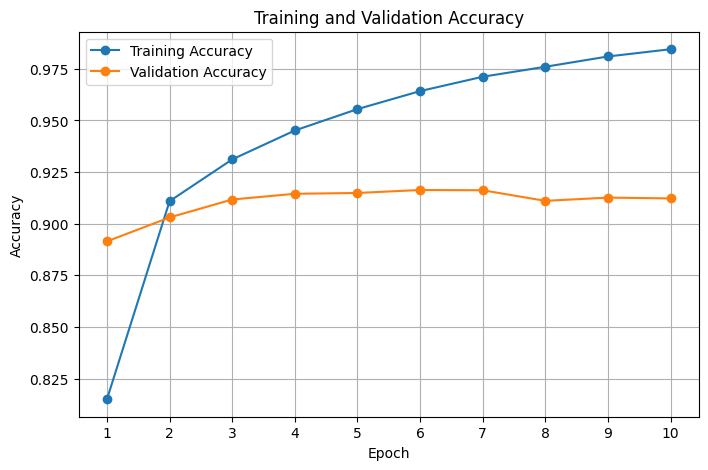

In [35]:
# Plot Training and Validation Accuracy

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, NUM_EPOCHS + 1),
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    range(1, NUM_EPOCHS + 1),
    val_accuracies,
    marker="o",
    label="Validation Accuracy"
)

plt.title("Training and Validation Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.xticks(range(1, NUM_EPOCHS + 1))

plt.grid(True)

plt.legend()

plt.show()

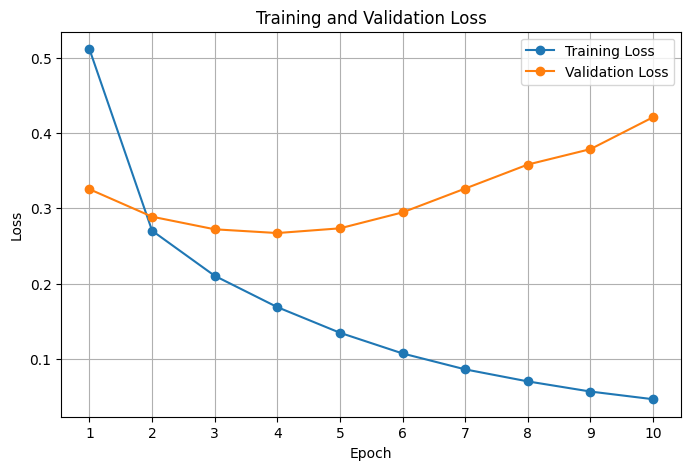

In [36]:
# Plot Training and Validation Loss

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, NUM_EPOCHS + 1),
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, NUM_EPOCHS + 1),
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.title("Training and Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.xticks(range(1, NUM_EPOCHS + 1))

plt.grid(True)

plt.legend()

plt.show()

# Step 13: Load the Best Trained Model

During training, we saved the model that achieved the highest validation accuracy.

In this step, we load that saved model into memory.

Using the best model instead of the last trained model usually gives better prediction performance because it represents the best-performing checkpoint during training.

In [37]:
# Create a new model with the same architecture
best_model = BiLSTMClassifier(
    vocab_size=len(itos),
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    output_dim=OUTPUT_DIM,
    padding_idx=PAD_IDX,
    dropout=DROPOUT
)

# Load the saved weights
best_model.load_state_dict(
    torch.load(
        "best_bilstm_ag_news.pth",
        map_location=device
    )
)

# Move model to GPU/CPU
best_model = best_model.to(device)

# Set evaluation mode
best_model.eval()

print("Best model loaded successfully!")

Best model loaded successfully!


# Step 14: Create a Prediction Function

Now we create a function that can classify any news headline.

The function performs the following steps:

1. Tokenizes the input text.
2. Converts words into numerical IDs.
3. Creates a batch of one sample.
4. Passes the input through the trained model.
5. Returns the predicted news category.

In [38]:
# Class names
class_names = [
    "World",
    "Sports",
    "Business",
    "Sci/Tech"
]


def predict(text, model):
    """
    Predict the news category for a single headline.
    """

    model.eval()

    # Convert text to word IDs
    text_ids = numericalize(text)

    # Convert to tensor
    text_tensor = torch.tensor(
        text_ids,
        dtype=torch.long
    ).unsqueeze(0)

    text_tensor = text_tensor.to(device)

    with torch.no_grad():

        outputs = model(text_tensor)

        prediction = outputs.argmax(dim=1).item()

    return class_names[prediction]

# Step 15: Test the Model on New Headlines

Finally, we test the trained model using several news headlines that were not part of the training examples.

This helps us understand how well the model generalizes to unseen text.

In [39]:
sample_headlines = [

    "Manchester United wins dramatic final in extra time",

    "NASA discovers a new Earth-like planet",

    "Stock market rises after interest rate announcement",

    "World leaders meet to discuss climate change",

    "Apple introduces its latest AI-powered iPhone"
]

for headline in sample_headlines:

    prediction = predict(
        headline,
        best_model
    )

    print(f"Headline : {headline}")
    print(f"Prediction : {prediction}")
    print("-" * 60)

Headline : Manchester United wins dramatic final in extra time
Prediction : Sports
------------------------------------------------------------
Headline : NASA discovers a new Earth-like planet
Prediction : Sci/Tech
------------------------------------------------------------
Headline : Stock market rises after interest rate announcement
Prediction : Business
------------------------------------------------------------
Headline : World leaders meet to discuss climate change
Prediction : Sci/Tech
------------------------------------------------------------
Headline : Apple introduces its latest AI-powered iPhone
Prediction : Sci/Tech
------------------------------------------------------------


# Project Summary

This project successfully developed a **Bidirectional LSTM (BiLSTM)** model for news text classification using the **AG News** dataset. The model was trained on the complete dataset containing **120,000 training samples** and evaluated on **7,600 test samples** across four categories: **World, Sports, Business, and Sci/Tech**.

During preprocessing, all news articles were tokenized, converted to lowercase, and transformed into numerical representations. A vocabulary of the **30,000 most frequent words** was created from the training data, resulting in a final vocabulary size of **30,002** including the special `<unk>` and `<pad>` tokens. News articles were then converted into sequences of word indices and padded to create uniform mini-batches for efficient training.

The proposed model consisted of an **Embedding layer**, a **Bidirectional LSTM**, a **Dropout layer (0.5)**, and a **Fully Connected output layer**. The network contained approximately **4.1 million trainable parameters**. The model was trained using the **Adam optimizer** with a learning rate of **0.001** and **CrossEntropyLoss** for **10 epochs** on a Tesla T4 GPU.

The training results showed that the model learned rapidly during the first few epochs. Training accuracy improved from **81.50%** in the first epoch to **98.45%** by the final epoch, while the validation accuracy reached its highest value of **91.63%**. The decreasing training loss demonstrated that the optimizer successfully minimized the classification error on the training dataset.

The accuracy and loss curves indicated that the model achieved its best generalization performance around **Epoch 4 to Epoch 6**. After this point, the training accuracy continued to improve, but the validation accuracy remained almost unchanged while the validation loss gradually increased. This behavior indicates the beginning of **overfitting**, where the model starts memorizing the training data instead of learning patterns that generalize well to unseen samples.

Despite this, the trained model performed well when tested on unseen news headlines. It correctly classified headlines related to **Sports**, **Business**, and **Sci/Tech**, demonstrating that it successfully learned meaningful semantic representations from the training data. Although one headline about world leaders discussing climate change was predicted as **Sci/Tech** instead of **World**, the overall predictions showed strong performance and good generalization ability.

Overall, the Bidirectional LSTM achieved a **best validation accuracy of 91.63%**, making it an effective model for news text classification. Future improvements such as **Early Stopping**, **pretrained word embeddings (GloVe or FastText)**, **learning rate scheduling**, **hyperparameter tuning**, or **Transformer-based models (e.g., BERT)** could further improve the model's accuracy and reduce overfitting.

# Comparison Between the Original LSTM and the Improved BiLSTM

Two text classification models were implemented using the AG News dataset. The first model was a simple LSTM trained on a small subset of the dataset, while the second model was an improved Bidirectional LSTM (BiLSTM) trained on the complete dataset. The comparison below highlights the differences in dataset usage, model architecture, training performance, and prediction results.

## Dataset Comparison

| Feature | Original LSTM | Improved BiLSTM |
|---------|---------------|-----------------|
| Training Samples | 5,000 | 120,000 |
| Testing Samples | 1,000 | 7,600 |
| Vocabulary Size | 65,017 | 30,002 |
| Training Epochs | 3 | 10 |

The original model was trained on only a small subset of the dataset to reduce training time, whereas the improved model was trained using the complete AG News dataset. The improved implementation also limited the vocabulary to the 30,000 most frequent words, resulting in a smaller and more efficient vocabulary.

---

## Model Comparison

| Feature | Original LSTM | Improved BiLSTM |
|---------|---------------|-----------------|
| Embedding Layer | ✓ | ✓ |
| LSTM Type | LSTM | Bidirectional LSTM |
| Dropout | No | Yes (0.5) |
| Trainable Parameters | 4,260,932 | 4,105,476 |

Although the improved model contains slightly fewer trainable parameters, it uses a Bidirectional LSTM together with dropout, allowing it to learn richer contextual information while helping reduce overfitting.

---

## Training Performance Comparison

| Metric | Original LSTM | Improved BiLSTM |
|--------|---------------|-----------------|
| Final Training Accuracy | 32.9% | 98.45% |
| Best Validation Accuracy | 40.5% | 91.63% |

The original LSTM showed gradual improvement during three training epochs but achieved only **40.5% validation accuracy**. In contrast, the improved BiLSTM achieved a **best validation accuracy of 91.63%** after training on the full dataset for ten epochs.

The improved model learned much faster and reached high accuracy within the first few epochs. The training and validation curves also showed that validation accuracy became stable around Epoch 4–6, while training accuracy continued to increase, indicating the beginning of overfitting.

---

## Prediction Comparison

### Original LSTM Predictions

| Headline | Prediction |
|----------|------------|
| Manchester United wins dramatic final in extra time | Business |
| Central bank raises interest rates to combat inflation | Sci/Tech |
| NASA's new telescope captures images of distant galaxy | Sci/Tech |
| Peace talks resume between the two neighboring countries | World |

The original model correctly classified the NASA and Peace Talks headlines but misclassified the Sports and Business headlines.

---

### Improved BiLSTM Predictions

| Headline | Prediction |
|----------|------------|
| Manchester United wins dramatic final in extra time | Sports |
| NASA discovers a new Earth-like planet | Sci/Tech |
| Stock market rises after interest rate announcement | Business |
| World leaders meet to discuss climate change | Sci/Tech |
| Apple introduces its latest AI-powered iPhone | Sci/Tech |

The improved BiLSTM produced more accurate predictions for unseen news headlines. It correctly classified the Sports, Business, and Sci/Tech examples, although the climate change headline was classified as Sci/Tech instead of World.

---

## Overall Comparison

| Category | Original LSTM | Improved BiLSTM |
|----------|---------------|-----------------|
| Training Dataset | 5,000 Samples | 120,000 Samples |
| Vocabulary | 65,017 | 30,002 |
| LSTM Architecture | Unidirectional | Bidirectional |
| Dropout | No | Yes |
| Training Epochs | 3 | 10 |
| Best Validation Accuracy | 40.5% | 91.63% |

## Conclusion

The improved Bidirectional LSTM significantly outperformed the original LSTM implementation. Training on the complete dataset, using a Bidirectional LSTM architecture, and incorporating dropout resulted in a substantial improvement in classification performance.

The best validation accuracy increased from **40.5%** to **91.63%**, demonstrating much better learning and generalization on unseen news articles. Overall, the improved BiLSTM provided more reliable and accurate predictions than the original LSTM while maintaining a similar model size.